# Práctica 3: Aprendizaje por Refuerzo

### Izan Cuesta Corbí

### Importación de librerías

In [1]:
!apt-get install -y swig
!pip install "gymnasium[box2d]" numpy matplotlib moviepy==1.0.3

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  swig4.0
Suggested packages:
  swig-doc swig-examples swig4.0-examples swig4.0-doc
The following NEW packages will be installed:
  swig swig4.0
0 upgraded, 2 newly installed, 0 to remove and 2 not upgraded.
Need to get 1,116 kB of archives.
After this operation, 5,542 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 swig4.0 amd64 4.0.2-1ubuntu1 [1,110 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 swig all 4.0.2-1ubuntu1 [5,632 B]
Fetched 1,116 kB in 0s (9,182 kB/s)
Selecting previously unselected package swig4.0.
(Reading database ... 118242 files and directories currently installed.)
Preparing to unpack .../swig4.0_4.0.2-1ubuntu1_amd64.deb ...
Unpacking swig4.0 (4.0.2-1ubuntu1) ...
Selecting previously unselected package swig.
Preparing to unpack .../swig_4.0.2-1ubun

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import moviepy.editor as mp
from IPython.display import Image, display
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from moviepy.video.io.ImageSequenceClip import ImageSequenceClip
import itertools
import pandas as pd
from google.colab import files
import os
os.environ["SDL_VIDEODRIVER"] = "dummy"

/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':



## Ejercicio 1: Política Aleatoria

#### Función GIF

In [3]:
def save_gif(frames, filename, fps=30):
    """
    Crea y serializa un archivo GIF a partir de un conjunto de frames RGB.
    """
    clip = mp.ImageSequenceClip(frames, fps=fps)
    clip.write_gif(filename, fps=fps)

#### Evaluación

In [9]:
# Configuración inicial
num_episodes = 100
episode_rewards = []
episode_lengths = []
frames_for_gif = []

print(f"Iniciando evaluación de agente aleatorio por {num_episodes} episodios...")

# Inicializamos el entorno con render_mode="rgb_array" para poder capturar los frames
env = gym.make("LunarLander-v3", render_mode="rgb_array")

# Bucle de Interacción Agente-Entorno
for episode in range(num_episodes):
    # Reseteamos el entorno al inicio de cada episodio
    obs, info = env.reset()
    done = False
    truncated = False

    total_reward = 0
    steps = 0

    while not done and not truncated:
        # Capturamos los frames solo del primer episodio para generar el GIF
        if episode == 0:
            frames_for_gif.append(env.render())

        # El agente selecciona una acción totalmente aleatoria
        action = env.action_space.sample()

        # El entorno ejecuta la acción y devuelve el nuevo estado y la recompensa
        obs, reward, done, truncated, info = env.step(action)

        total_reward += reward
        steps += 1

    episode_rewards.append(total_reward)
    episode_lengths.append(steps)

# Cerramos el entorno
env.close()

save_gif(frames_for_gif, "lunarlander_aleatorio.gif")

mean_reward = np.mean(episode_rewards)
std_reward = np.std(episode_rewards)
mean_length = np.mean(episode_lengths)
std_length = np.std(episode_lengths)

print("\nRESULTADOS DE LA EVALUACIÓN")
print(f"Recompensa Media: {mean_reward:.2f} ± {std_reward:.2f}")
print(f"Duración Media (pasos): {mean_length:.2f} ± {std_length:.2f}")

Iniciando evaluación de agente aleatorio por 100 episodios...
MoviePy - Building file lunarlander_aleatorio.gif with imageio.



RESULTADOS DE LA EVALUACIÓN
Recompensa Media: -178.19 ± 110.27
Duración Media (pasos): 89.23 ± 20.39


#### Gráficas y visualización

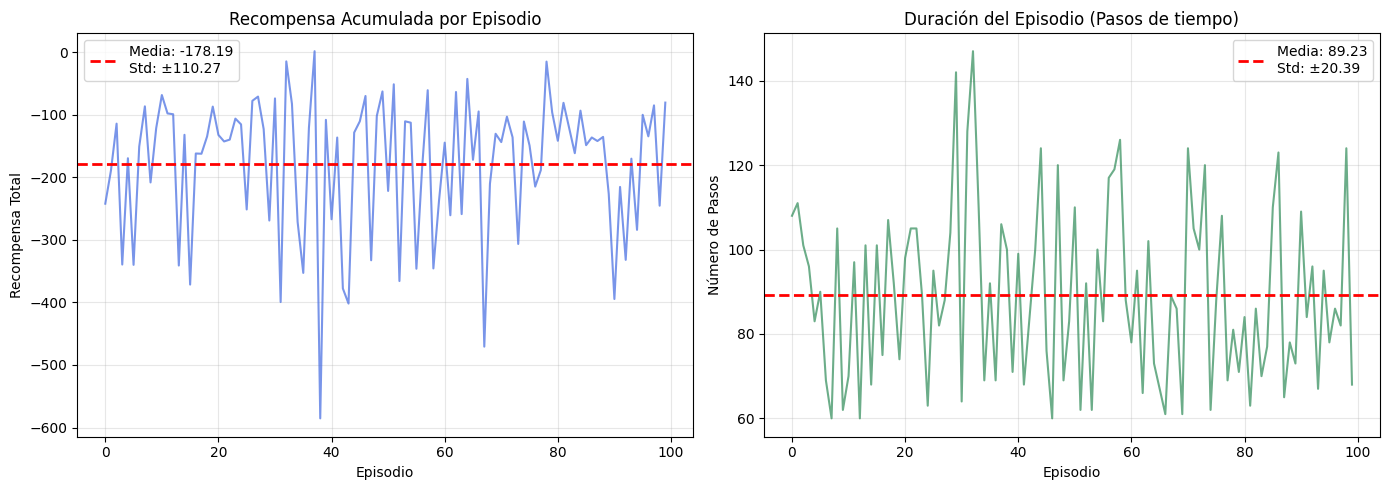

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Recompensa Acumulada
ax1.plot(episode_rewards, color='royalblue', alpha=0.7)
ax1.axhline(mean_reward, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_reward:.2f}\nStd: ±{std_reward:.2f}')
ax1.set_title('Recompensa Acumulada por Episodio')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Gráfica 2: Duración del Episodio
ax2.plot(episode_lengths, color='seagreen', alpha=0.7)
ax2.axhline(mean_length, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_length:.2f}\nStd: ±{std_length:.2f}')
ax2.set_title('Duración del Episodio (Pasos de tiempo)')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_aleatorios.png", dpi=300)
plt.show()

#### GIF generado

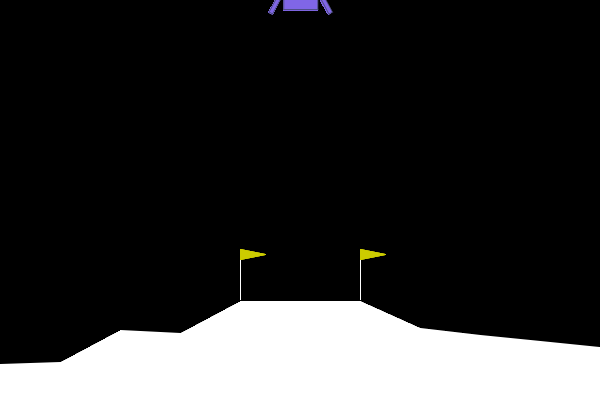

In [13]:
display(Image(filename="lunarlander_aleatorio.gif"))

In [15]:
files.download("resultados_aleatorios.png")
files.download("lunarlander_aleatorio.gif")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Ejercicio 2: REINFORCE

#### Definición de la red neuronal (Agente)

In [58]:
class PolicyNetwork(nn.Module):
    def __init__(self, input_shape, n_actions, n_hidden):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(input_shape, n_hidden)
        self.fc2 = nn.Linear(n_hidden, n_hidden)
        self.fc3 = nn.Linear(n_hidden, n_actions)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        distribution = torch.distributions.Categorical(logits=x)
        action = distribution.sample()
        entropy = distribution.entropy()
        log_prob = distribution.log_prob(action)
        return action, log_prob, entropy

#### Análisis de hiperparámetros

In [37]:
def train_fast_search(lr, gamma, n_hidden, optim_name, episodes=300):
    env = gym.make("LunarLander-v3")
    n_states = env.observation_space.shape[0]
    n_actions = env.action_space.n

    policy = PolicyNetwork(n_states, n_actions, n_hidden)

    if optim_name == "Adam":
        optimizer = optim.Adam(policy.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(policy.parameters(), lr=lr)

    train_rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        log_probs, rewards = [], []
        done = truncated = False

        while not done and not truncated:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            action, log_prob, *_ = policy(state_tensor)
            state, reward, done, truncated, _ = env.step(action.item())

            log_probs.append(log_prob)
            rewards.append(reward)

        train_rewards.append(sum(rewards))

        returns, G = [], 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)
        returns = torch.tensor(returns, dtype=torch.float32)

        policy_loss = []
        for lp, G_t in zip(log_probs, returns):
            policy_loss.append(-lp * G_t)
        loss = torch.cat(policy_loss).sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    env.close()
    return train_rewards

print("BÚSQUEDA RÁPIDA DE HIPERPARÁMETROS (300 Episodios)")

configs = [
    {"lr": 1e-3, "gamma": 0.99, "n_hidden": 128, "optim": "Adam"}, # Base
    {"lr": 1e-2, "gamma": 0.99, "n_hidden": 128, "optim": "Adam"}, # LR Alto
    {"lr": 1e-4, "gamma": 0.99, "n_hidden": 128, "optim": "Adam"}, # LR Bajo
    {"lr": 1e-3, "gamma": 0.50, "n_hidden": 128, "optim": "Adam"}, # Gamma Bajo
    {"lr": 1e-3, "gamma": 0.99, "n_hidden": 64,  "optim": "Adam"}, # Menos neuronas
    {"lr": 1e-3, "gamma": 0.99, "n_hidden": 256, "optim": "Adam"}, # Más neuronas
    {"lr": 1e-3, "gamma": 0.99, "n_hidden": 128, "optim": "SGD"}   # SGD
]

results_data = []

for cfg in configs:
    print(f"Probando -> LR: {cfg['lr']} | Gamma: {cfg['gamma']:0.2f} | Hidden: {cfg['n_hidden']:3d} | Optim: {cfg['optim']}", end=" ")

    rewards = train_fast_search(lr=cfg['lr'], gamma=cfg['gamma'], n_hidden=cfg['n_hidden'], optim_name=cfg['optim'], episodes=300)

    score = np.mean(rewards[-50:])
    print(f"Score: {score:.2f}")

    results_data.append({
        "Optimizador": cfg['optim'],
        "LR": cfg['lr'],
        "Gamma": cfg['gamma'],
        "Hidden": cfg['n_hidden'],
        "Score (50 ep)": score
    })

df_results = pd.DataFrame(results_data)
df_results = df_results.sort_values(by="Score (50 ep)", ascending=False).reset_index(drop=True)
display(df_results)

BÚSQUEDA RÁPIDA DE HIPERPARÁMETROS (300 Episodios)
Probando -> LR: 0.001 | Gamma: 0.99 | Hidden: 128 | Optim: Adam Score: -142.33
Probando -> LR: 0.01 | Gamma: 0.99 | Hidden: 128 | Optim: Adam Score: -130.79
Probando -> LR: 0.0001 | Gamma: 0.99 | Hidden: 128 | Optim: Adam Score: -149.51
Probando -> LR: 0.001 | Gamma: 0.50 | Hidden: 128 | Optim: Adam Score: -133.29
Probando -> LR: 0.001 | Gamma: 0.99 | Hidden:  64 | Optim: Adam Score: -142.19
Probando -> LR: 0.001 | Gamma: 0.99 | Hidden: 256 | Optim: Adam Score: -140.66
Probando -> LR: 0.001 | Gamma: 0.99 | Hidden: 128 | Optim: SGD Score: -548.72


,Optimizador,LR,Gamma,Hidden,Score (50 ep)
0,Adam,0.0100,0.99,128,-130.789126
1,Adam,0.0010,0.50,128,-133.288845
2,Adam,0.0010,0.99,256,-140.656595
3,Adam,0.0010,0.99,64,-142.192757
4,Adam,0.0010,0.99,128,-142.334661
5,Adam,0.0001,0.99,128,-149.505099
6,SGD,0.0010,0.99,128,-548.718167


#### Entrenamiento y evaluación BASE

In [49]:
# ENTRENAMIENTO (VERSIÓN BASE)
print("FASE A: ENTRENAMIENTO (REINFORCE BASE)")

# Hiperparámetros
LEARNING_RATE = 1e-3
GAMMA = 0.99
N_HIDDEN = 128
TRAIN_EPISODES = 1000

# Inicialización del entorno
env_train_base = gym.make("LunarLander-v3")
n_states_base = env_train_base.observation_space.shape[0]
n_actions_base = env_train_base.action_space.n

# Instanciar la red y el optimizador con nombres diferenciados
policy_base = PolicyNetwork(n_states_base, n_actions_base, N_HIDDEN)
optimizer_base = optim.Adam(policy_base.parameters(), lr=LEARNING_RATE)

train_rewards_base = []
train_lengths_base = []

for episode in range(TRAIN_EPISODES):
    state, _ = env_train_base.reset()
    log_probs_base = []
    rewards_base = []
    done = False
    truncated = False

    # Recolección de la trayectoria
    while not done and not truncated:
        state_tensor = torch.FloatTensor(state).unsqueeze(0)

        # Ignoramos la entropía que devuelve el forward usando "_"
        action, log_prob, _ = policy_base(state_tensor)

        next_state, reward, done, truncated, _ = env_train_base.step(action.item())

        log_probs_base.append(log_prob)
        rewards_base.append(reward)

        state = next_state

    train_rewards_base.append(sum(rewards_base))
    train_lengths_base.append(len(rewards_base))

    # Cálculo de Retornos Descontados (G_t) sin normalizar
    returns_base = []
    G = 0
    for r in reversed(rewards_base):
        G = r + GAMMA * G
        returns_base.insert(0, G)
    returns_base = torch.tensor(returns_base)

    # Construcción de la Función de Pérdida (Loss) sin bonus de entropía
    policy_loss_base = []
    for log_prob, G in zip(log_probs_base, returns_base):
        policy_loss_base.append(-log_prob * G)

    loss_base = torch.cat(policy_loss_base).sum()

    # Paso de Optimización
    optimizer_base.zero_grad()
    loss_base.backward()
    optimizer_base.step()

    # Progreso
    if (episode + 1) % 100 == 0:
        avg_reward = np.mean(train_rewards_base[-100:])
        print(f"Episodio {episode + 1}/{TRAIN_EPISODES} | Recompensa media: {avg_reward:.2f}")

env_train_base.close()

# Cálculo de métricas base
mean_tr_v_base = np.mean(train_rewards_base)
std_tr_v_base  = np.std(train_rewards_base)
mean_tl_v_base = np.mean(train_lengths_base)
std_tl_v_base  = np.std(train_lengths_base)

print(f"\nRecompensa Base: {mean_tr_v_base:.2f} ± {std_tr_v_base:.2f} | Pasos: {mean_tl_v_base:.2f} ± {std_tl_v_base:.2f}")

# EVALUACIÓN (VERSIÓN BASE)
print("\nFASE B: EVALUACIÓN (REINFORCE BASE)")
EVAL_EPISODES = 100
eval_rewards_base = []
eval_lengths_base = []
frames_for_gif_base = []

env_eval_base = gym.make("LunarLander-v3", render_mode="rgb_array")
policy_base.eval()

for episode in range(EVAL_EPISODES):
    state, _ = env_eval_base.reset()
    done = False
    truncated = False
    total_reward = 0
    steps = 0

    while not done and not truncated:
        if episode == 0:
            frames_for_gif_base.append(env_eval_base.render())

        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            # Ignoramos de nuevo la entropía en evaluación
            action, _, _ = policy_base(state_tensor)

        state, reward, done, truncated, _ = env_eval_base.step(action.item())
        total_reward += reward
        steps += 1

    eval_rewards_base.append(total_reward)
    eval_lengths_base.append(steps)

env_eval_base.close()

# Cálculo de métricas de evaluación base
mean_ev_v_base = np.mean(eval_rewards_base)
std_ev_v_base  = np.std(eval_rewards_base)
mean_el_v_base = np.mean(eval_lengths_base)
std_el_v_base  = np.std(eval_lengths_base)

print(f"Recompensa Eval Base: {mean_ev_v_base:.2f} ± {std_ev_v_base:.2f} | Pasos: {mean_el_v_base:.2f} ± {std_el_v_base:.2f}")

save_gif(frames_for_gif_base, "lunarlander_reinforce_base.gif")

FASE A: ENTRENAMIENTO (REINFORCE BASE)
Episodio 100/1000 | Recompensa media: -194.21
Episodio 200/1000 | Recompensa media: -159.60
Episodio 300/1000 | Recompensa media: -161.54
Episodio 400/1000 | Recompensa media: -165.76
Episodio 500/1000 | Recompensa media: -140.72
Episodio 600/1000 | Recompensa media: -130.18
Episodio 700/1000 | Recompensa media: -130.56
Episodio 800/1000 | Recompensa media: -123.34
Episodio 900/1000 | Recompensa media: -121.35
Episodio 1000/1000 | Recompensa media: -115.22

Recompensa Base: -144.25 ± 67.70 | Pasos: 80.53 ± 17.83

FASE B: EVALUACIÓN (REINFORCE BASE)
Recompensa Eval Base: -102.04 ± 36.74 | Pasos: 90.61 ± 19.89
MoviePy - Building file lunarlander_reinforce_base.gif with imageio.


#### Gráficas de entrenamiento BASE

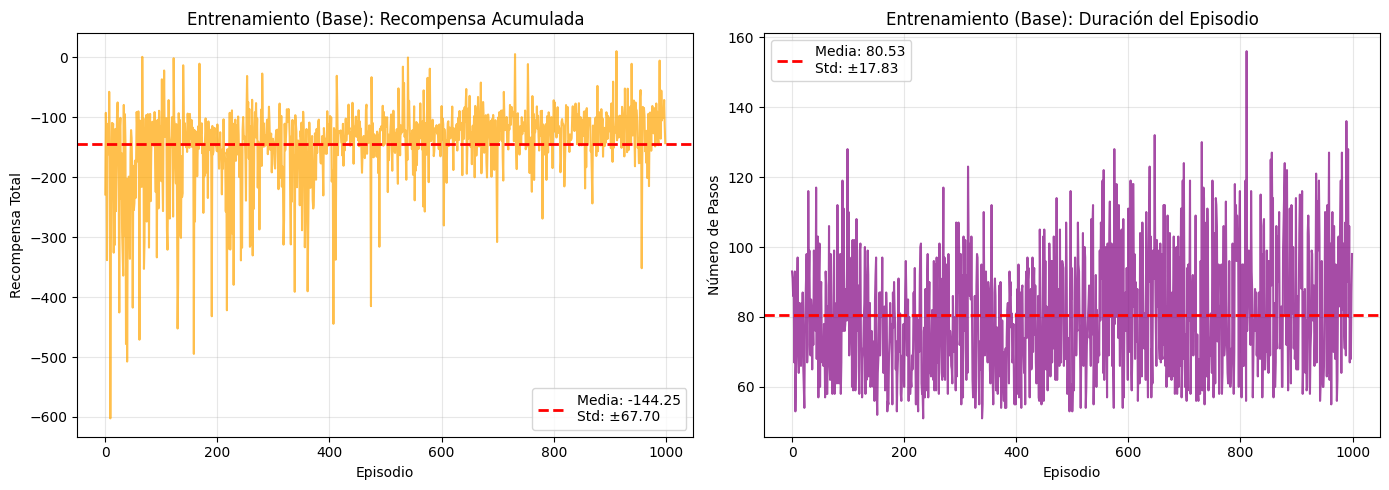

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Entrenamiento: Recompensa
ax1.plot(train_rewards_base, color='orange', alpha=0.7)
ax1.axhline(mean_tr_v_base, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_tr_v_base:.2f}\nStd: ±{std_tr_v_base:.2f}')
ax1.set_title('Entrenamiento (Base): Recompensa Acumulada')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Entrenamiento: Longitud
ax2.plot(train_lengths_base, color='purple', alpha=0.7)
ax2.axhline(mean_tl_v_base, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_tl_v_base:.2f}\nStd: ±{std_tl_v_base:.2f}')
ax2.set_title('Entrenamiento (Base): Duración del Episodio')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_reinforce_base_train.png", dpi=300)
plt.show()

#### Gráficas de evaluación base

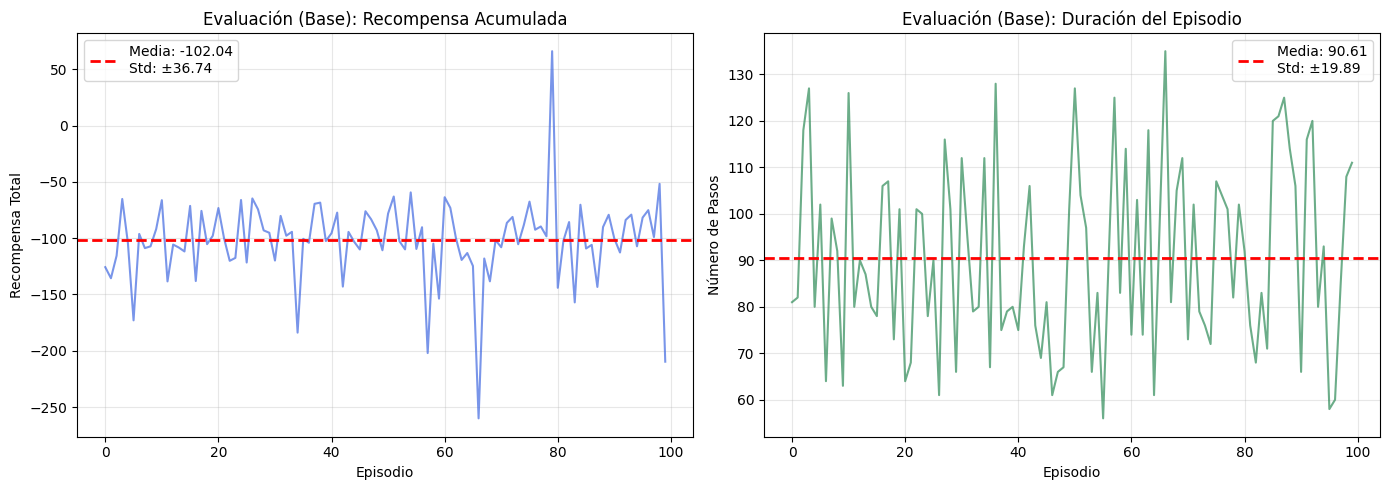

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Evaluación: Recompensa
ax1.plot(eval_rewards_base, color='royalblue', alpha=0.7)
ax1.axhline(mean_ev_v_base, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_ev_v_base:.2f}\nStd: ±{std_ev_v_base:.2f}')
ax1.set_title('Evaluación (Base): Recompensa Acumulada')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Evaluación: Longitud
ax2.plot(eval_lengths_base, color='seagreen', alpha=0.7)
ax2.axhline(mean_el_v_base, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_el_v_base:.2f}\nStd: ±{std_el_v_base:.2f}')
ax2.set_title('Evaluación (Base): Duración del Episodio')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_reinforce_base_eval.png", dpi=300)
plt.show()

#### GIF generado

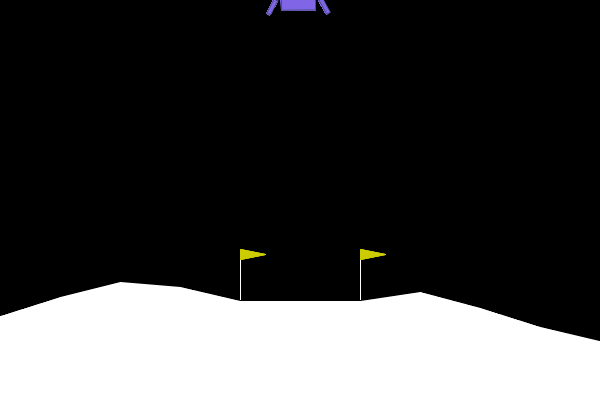

In [52]:
display(Image(filename="lunarlander_reinforce_base.gif"))

In [53]:
files.download("lunarlander_reinforce_base.gif")
files.download("resultados_reinforce_base_train.png")
files.download("resultados_reinforce_base_eval.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### REINFORCE MEJORADO (OPCIONAL)

#### Entrenamiento y Evaluación

In [54]:
# ENTRENAMIENTO
print("FASE A: ENTRENAMIENTO")

# Hiperparámetros
LEARNING_RATE = 1e-3
GAMMA = 0.99
N_HIDDEN = 128
ENTROPY_BETA = 0.01
TRAIN_EPISODES = 1000

# Inicialización del entorno
env_train = gym.make("LunarLander-v3")
n_states = env_train.observation_space.shape[0]
n_actions = env_train.action_space.n

# Instanciar la red y el optimizador (Adam)
policy = PolicyNetwork(n_states, n_actions, N_HIDDEN)
optimizer = optim.Adam(policy.parameters(), lr=LEARNING_RATE)

train_rewards = []
train_lengths = []

for episode in range(TRAIN_EPISODES):
    state, _ = env_train.reset()
    log_probs = []
    rewards = []
    entropies = []
    done = False
    truncated = False

    # Recolección de la trayectoria
    while not done and not truncated:
        # Convertir estado a tensor de PyTorch
        state_tensor = torch.FloatTensor(state).unsqueeze(0)

        # Obtener acción, log_prob y entropía de la red
        action, log_prob, entropy = policy(state_tensor)

        # Ejecutar acción en el entorno
        next_state, reward, done, truncated, _ = env_train.step(action.item())

        log_probs.append(log_prob)
        rewards.append(reward)
        entropies.append(entropy)

        state = next_state

    train_rewards.append(sum(rewards))
    train_lengths.append(len(rewards))

    # Cálculo de Retornos Descontados (G_t)
    returns = []
    G = 0
    # Calculamos de atrás hacia adelante
    for r in reversed(rewards):
        G = r + GAMMA * G
        returns.insert(0, G)
    returns = torch.tensor(returns)

    returns = (returns - returns.mean()) / (returns.std() + 1e-9)

    # Construcción de la Función de Pérdida (Loss)
    policy_loss = []
    for log_prob, G in zip(log_probs, returns):
        policy_loss.append(-log_prob * G)

    # Sumamos las pérdidas y restamos el bonus de entropía para fomentar exploración
    loss = torch.cat(policy_loss).sum() - ENTROPY_BETA * torch.cat(entropies).sum()

    # Paso de Optimización (Retropropagación)
    optimizer.zero_grad() # Limpiar gradientes anteriores
    loss.backward()       # Calcular nuevos gradientes
    optimizer.step()      # Actualizar los pesos de la red

    # Progreso
    if (episode + 1) % 100 == 0:
        avg_reward = np.mean(train_rewards[-100:])
        print(f"Episodio {episode + 1}/{TRAIN_EPISODES} | Recompensa media (últimos 100): {avg_reward:.2f}")

env_train.close()

mean_tr_v = np.mean(train_rewards)
std_tr_v  = np.std(train_rewards)
mean_tl_v = np.mean(train_lengths)
std_tl_v  = np.std(train_lengths)
print(f"\nRecompensa: {mean_tr_v:.2f} ± {std_tr_v:.2f} | "
      f"Pasos: {mean_tl_v:.2f} ± {std_tl_v:.2f}")

# EVALUACIÓN
print("\nFASE B: EVALUACIÓN")
EVAL_EPISODES = 100
eval_rewards = []
eval_lengths = []
frames_for_gif = []

# Entorno con render_mode para el GIF
env_eval = gym.make("LunarLander-v3", render_mode="rgb_array")

policy.eval()

for episode in range(EVAL_EPISODES):
    state, _ = env_eval.reset()
    done = False
    truncated = False
    total_reward = 0
    steps = 0

    while not done and not truncated:
        if episode == 0:
            frames_for_gif.append(env_eval.render())

        # En evaluación, no necesitamos calcular gradientes
        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            action, _, _ = policy(state_tensor)

        state, reward, done, truncated, _ = env_eval.step(action.item())
        total_reward += reward
        steps += 1

    eval_rewards.append(total_reward)
    eval_lengths.append(steps)

env_eval.close()

mean_ev_v = np.mean(eval_rewards)
std_ev_v  = np.std(eval_rewards)
mean_el_v = np.mean(eval_lengths)
std_el_v  = np.std(eval_lengths)
print(f"Recompensa: {mean_ev_v:.2f} ± {std_ev_v:.2f} | "
      f"Pasos: {mean_el_v:.2f} ± {std_el_v:.2f}")

save_gif(frames_for_gif, "lunarlander_reinforce.gif")

FASE A: ENTRENAMIENTO
Episodio 100/1000 | Recompensa media (últimos 100): -152.94
Episodio 200/1000 | Recompensa media (últimos 100): -100.51
Episodio 300/1000 | Recompensa media (últimos 100): -49.93
Episodio 400/1000 | Recompensa media (últimos 100): -64.53
Episodio 500/1000 | Recompensa media (últimos 100): 10.26
Episodio 600/1000 | Recompensa media (últimos 100): 16.75
Episodio 700/1000 | Recompensa media (últimos 100): 33.95
Episodio 800/1000 | Recompensa media (últimos 100): 77.91
Episodio 900/1000 | Recompensa media (últimos 100): 108.16
Episodio 1000/1000 | Recompensa media (últimos 100): 79.00

Recompensa: -4.19 ± 106.65 | Pasos: 415.45 ± 392.38

FASE B: EVALUACIÓN
Recompensa: 90.31 ± 64.36 | Pasos: 658.99 ± 409.28
MoviePy - Building file lunarlander_reinforce.gif with imageio.


#### Gráficas de entrenamiento

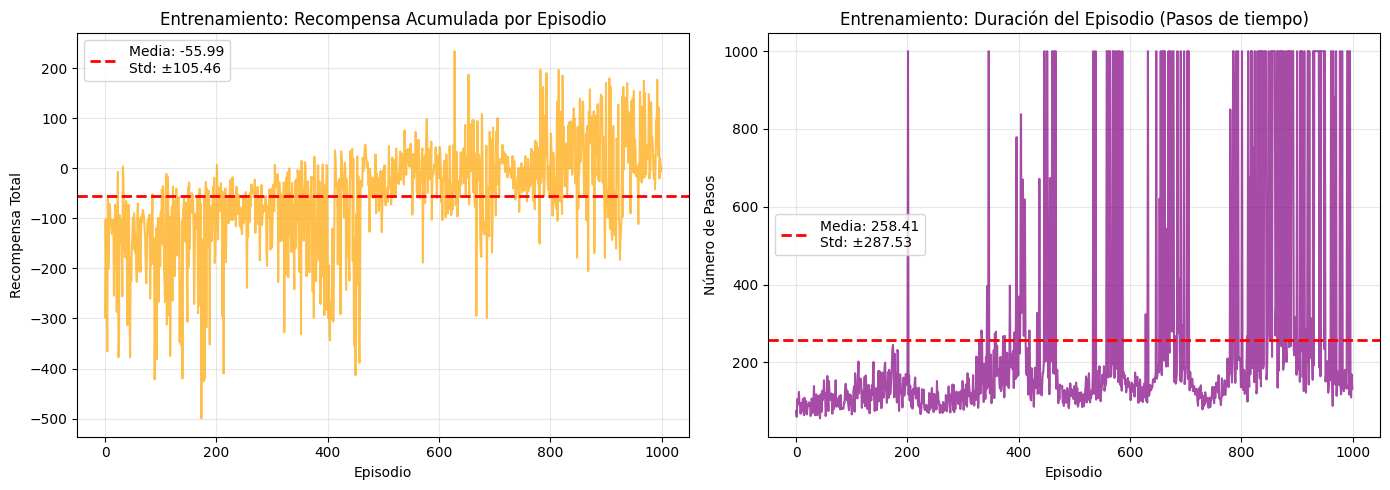

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Entrenamiento: Recompensa
ax1.plot(train_rewards, color='orange', alpha=0.7)
ax1.axhline(mean_tr_v, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_tr_v:.2f}\nStd: ±{std_tr_v:.2f}')
ax1.set_title('Entrenamiento: Recompensa Acumulada por Episodio')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Entrenamiento: Longitud
ax2.plot(train_lengths, color='purple', alpha=0.7)
ax2.axhline(mean_tl_v, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_tl_v:.2f}\nStd: ±{std_tl_v:.2f}')
ax2.set_title('Entrenamiento: Duración del Episodio (Pasos de tiempo)')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_reinforce_train.png", dpi=300)
plt.show()

#### Gráficas de evaluación

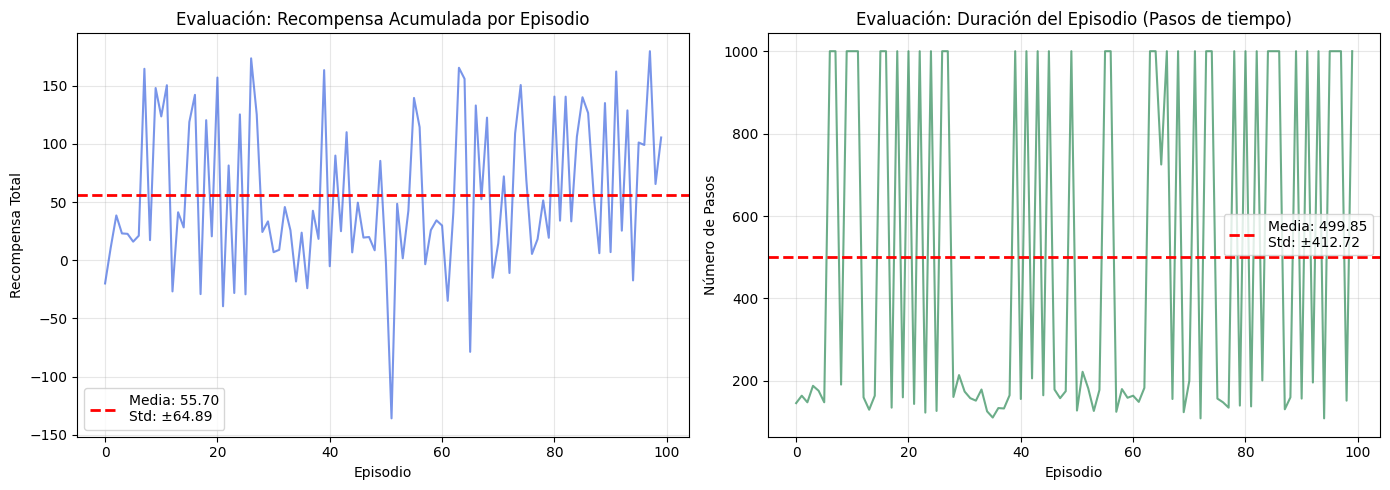

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Evaluación: Recompensa
ax1.plot(eval_rewards, color='royalblue', alpha=0.7)
ax1.axhline(mean_ev_v, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_ev_v:.2f}\nStd: ±{std_ev_v:.2f}')
ax1.set_title('Evaluación: Recompensa Acumulada por Episodio')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Evaluación: Longitud
ax2.plot(eval_lengths, color='seagreen', alpha=0.7)
ax2.axhline(mean_el_v, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_el_v:.2f}\nStd: ±{std_el_v:.2f}')
ax2.set_title('Evaluación: Duración del Episodio (Pasos de tiempo)')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_reinforce_eval.png", dpi=300)
plt.show()

#### GIF generado

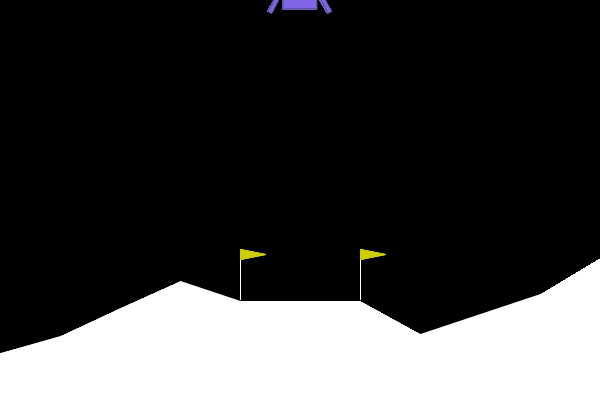

In [33]:
display(Image(filename="lunarlander_reinforce.gif"))

In [34]:
files.download("lunarlander_reinforce.gif")
files.download("resultados_reinforce_train.png")
files.download("resultados_reinforce_eval.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Ejercicio 3: REINFORCE con Línea Base

#### Arquitectura del Crítico

In [62]:
class ValueNetwork(nn.Module):
    def __init__(self, n_features, n_hidden):
        super(ValueNetwork, self).__init__()
        self.fc1 = nn.Linear(n_features, n_hidden)
        self.fc2 = nn.Linear(n_hidden, n_hidden)
        self.fc3 = nn.Linear(n_hidden, 1)

    def forward(self, x) -> torch.Tensor:
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

#### Entrenamiento y evaluación

In [63]:
print("FASE A: ENTRENAMIENTO - REINFORCE BASELINE")

LR_ACTOR       = 1e-3
LR_CRITIC      = 5e-3
GAMMA          = 0.99
N_HIDDEN       = 128
TRAIN_EPISODES = 1000

env_train = gym.make("LunarLander-v3")
n_states  = env_train.observation_space.shape[0]
n_actions = env_train.action_space.n

# Instanciar Actor y Crítico
actor  = PolicyNetwork(n_states, n_actions, N_HIDDEN)
critic = ValueNetwork(n_states, N_HIDDEN)

# Un optimizador por red
optimizer_actor  = optim.Adam(actor.parameters(),  lr=LR_ACTOR)
optimizer_critic = optim.Adam(critic.parameters(), lr=LR_CRITIC)

mse_loss_fn = nn.MSELoss()

train_rewards_baseline = []
train_lengths_baseline = []

for episode in range(TRAIN_EPISODES):
    state, _ = env_train.reset()
    states, log_probs, rewards = [], [], []
    done = truncated = False

    # Recolección de trayectoria completa
    while not done and not truncated:
        state_tensor = torch.FloatTensor(state).unsqueeze(0)
        action, log_prob, _ = actor(state_tensor)
        state, reward, done, truncated, _ = env_train.step(action.item())

        states.append(state_tensor)
        log_probs.append(log_prob)
        rewards.append(reward)

    train_rewards_baseline.append(sum(rewards))
    train_lengths_baseline.append(len(rewards))

    # Retornos descontados G_t
    returns, G = [], 0
    for r in reversed(rewards):
        G = r + GAMMA * G
        returns.insert(0, G)
    returns = torch.tensor(returns, dtype=torch.float32)

    # Estimación del Crítico V(s_t)
    states_tensor = torch.cat(states)
    values = critic(states_tensor).squeeze()

    # Ventaja A(s_t, a_t)
    advantages = returns - values.detach()

    # Pérdida del Crítico
    critic_loss = mse_loss_fn(values, returns)

    # Pérdida del Actor
    actor_loss = torch.cat(
        [-lp * adv for lp, adv in zip(log_probs, advantages)]
    ).sum()

    # Actualización del Crítico
    optimizer_critic.zero_grad()
    critic_loss.backward()
    optimizer_critic.step()

    # Actualización del Actor
    optimizer_actor.zero_grad()
    actor_loss.backward()
    optimizer_actor.step()

    if (episode + 1) % 100 == 0:
        avg = np.mean(train_rewards_baseline[-100:])
        print(f"  Ep {episode+1:4d} | Media últimos 100: {avg:.2f}")

env_train.close()

mean_train_rew = np.mean(train_rewards_baseline)
std_train_rew  = np.std(train_rewards_baseline)
mean_train_len = np.mean(train_lengths_baseline)
std_train_len  = np.std(train_lengths_baseline)

print(f"  Recompensa media: {mean_train_rew:.2f} ± {std_train_rew:.2f}")
print(f"  Pasos medios:     {mean_train_len:.2f} ± {std_train_len:.2f}")

# EVALUACIÓN
print("\nFASE B: EVALUACIÓN")

EVAL_EPISODES = 100
eval_rewards, eval_lengths = [], []
frames_for_gif = []

env_eval = gym.make("LunarLander-v3", render_mode="rgb_array")
actor.eval()

for episode in range(EVAL_EPISODES):
    state, _ = env_eval.reset()
    done = truncated = False
    total_reward, steps = 0, 0

    while not done and not truncated:
        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            action, _, _ = actor(state_tensor)

        state, reward, done, truncated, _ = env_eval.step(action.item())
        total_reward += reward
        steps += 1
        if episode == 0:
            frames_for_gif.append(env_eval.render())

    eval_rewards.append(total_reward)
    eval_lengths.append(steps)

env_eval.close()
save_gif(frames_for_gif, "lunarlander_baseline.gif")

mean_eval_rew = np.mean(eval_rewards)
std_eval_rew  = np.std(eval_rewards)
mean_eval_len = np.mean(eval_lengths)
std_eval_len  = np.std(eval_lengths)

print(f"  Recompensa media: {mean_eval_rew:.2f} ± {std_eval_rew:.2f}")
print(f"  Pasos medios:     {mean_eval_len:.2f} ± {std_eval_len:.2f}")



FASE A: ENTRENAMIENTO - REINFORCE BASELINE
  Ep  100 | Media últimos 100: -159.74
  Ep  200 | Media últimos 100: -143.32
  Ep  300 | Media últimos 100: -87.09
  Ep  400 | Media últimos 100: -52.17
  Ep  500 | Media últimos 100: -27.99
  Ep  600 | Media últimos 100: 9.72
  Ep  700 | Media últimos 100: 27.46
  Ep  800 | Media últimos 100: 78.66
  Ep  900 | Media últimos 100: 104.02
  Ep 1000 | Media últimos 100: 162.57
  Recompensa media: -8.79 ± 123.05
  Pasos medios:     373.95 ± 368.89

FASE B: EVALUACIÓN
MoviePy - Building file lunarlander_baseline.gif with imageio.


  Recompensa media: 188.56 ± 95.13
  Pasos medios:     432.87 ± 78.22


#### Gráficas de entrenamiento

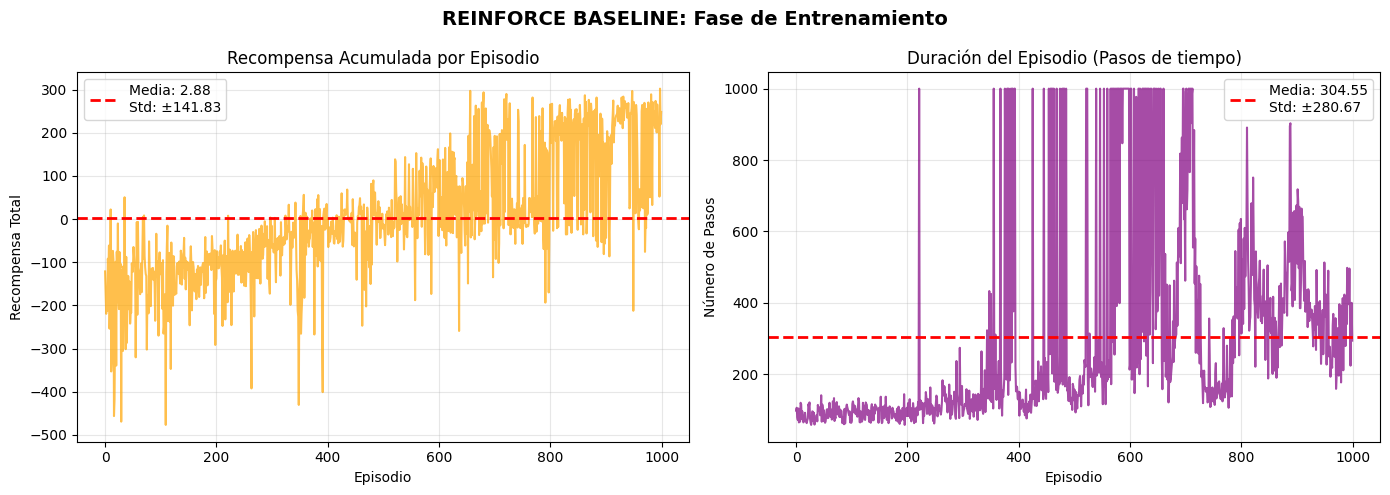

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("REINFORCE BASELINE: Fase de Entrenamiento", fontsize=14, fontweight='bold')

# Entrenamiento: Recompensa
ax1.plot(train_rewards_baseline, color='orange', alpha=0.7)
ax1.axhline(mean_train_rew, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_train_rew:.2f}\nStd: ±{std_train_rew:.2f}')
ax1.set_title('Recompensa Acumulada por Episodio')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Entrenamiento: Longitud
ax2.plot(train_lengths_baseline, color='purple', alpha=0.7)
ax2.axhline(mean_train_len, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_train_len:.2f}\nStd: ±{std_train_len:.2f}')
ax2.set_title('Duración del Episodio (Pasos de tiempo)')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_baseline_train.png", dpi=300)
plt.show()

#### Gráficas de evaluación

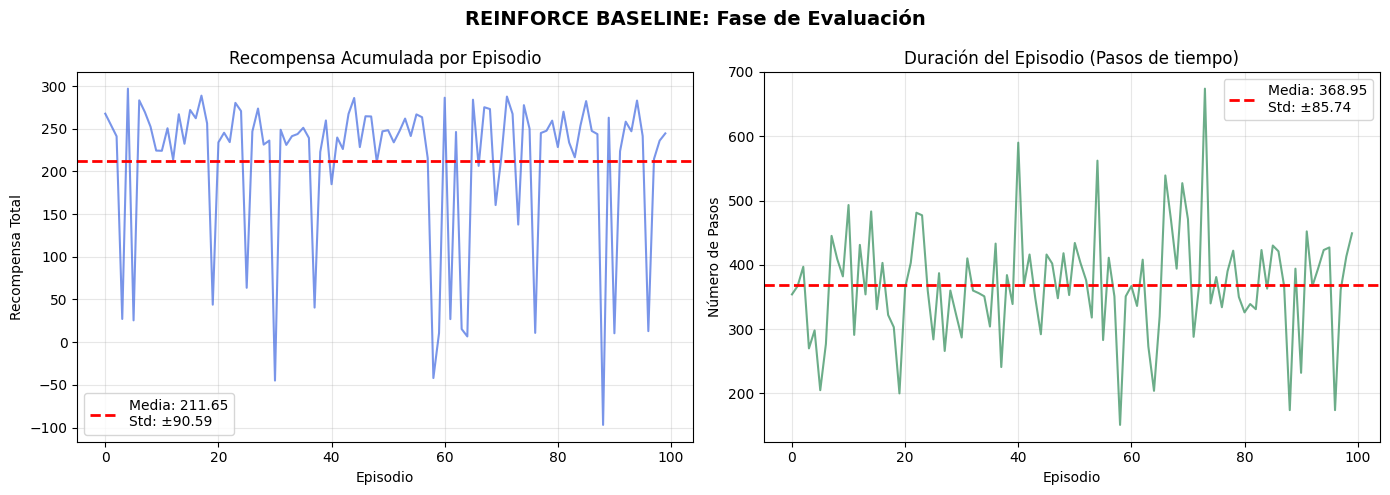

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("REINFORCE BASELINE: Fase de Evaluación", fontsize=14, fontweight='bold')

# Evaluación: Recompensa
ax1.plot(eval_rewards, color='royalblue', alpha=0.7)
ax1.axhline(mean_eval_rew, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_eval_rew:.2f}\nStd: ±{std_eval_rew:.2f}')
ax1.set_title('Recompensa Acumulada por Episodio')
ax1.set_xlabel('Episodio')
ax1.set_ylabel('Recompensa Total')
ax1.legend()
ax1.grid(alpha=0.3)

# Evaluación: Longitud
ax2.plot(eval_lengths, color='seagreen', alpha=0.7)
ax2.axhline(mean_eval_len, color='red', linestyle='dashed', linewidth=2,
            label=f'Media: {mean_eval_len:.2f}\nStd: ±{std_eval_len:.2f}')
ax2.set_title('Duración del Episodio (Pasos de tiempo)')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Número de Pasos')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("resultados_baseline_eval.png", dpi=300)
plt.show()

#### GIF generado

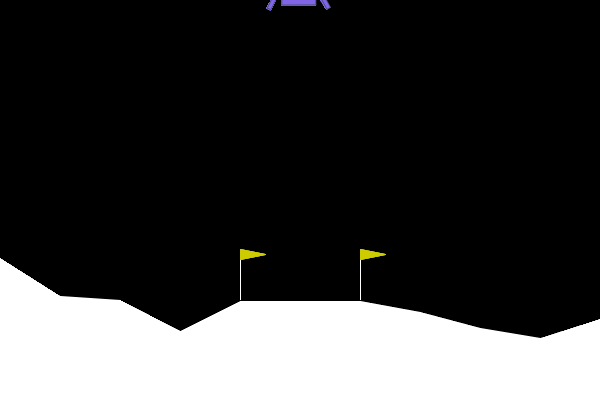

In [46]:
display(Image(filename="lunarlander_baseline.gif"))

In [47]:
files.download("lunarlander_baseline.gif")
files.download("resultados_baseline_train.png")
files.download("resultados_baseline_eval.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Comparación global

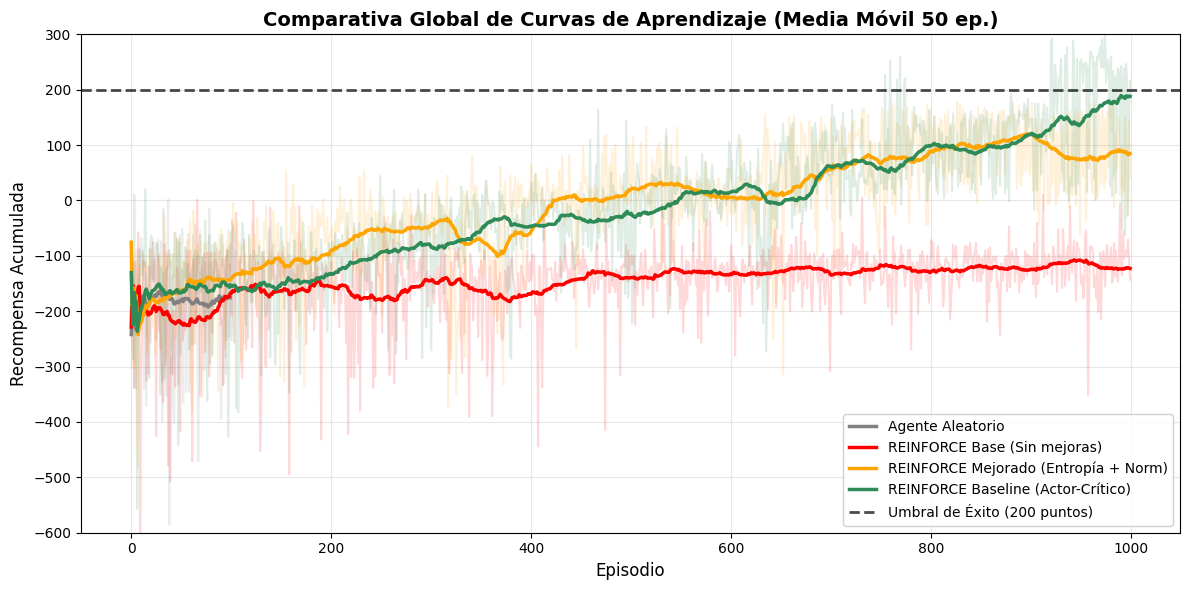

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
# Ejercicio 1
recompensas_aleatorio = episode_rewards

# Ejercicio 2
recompensas_base = train_rewards_base

# Ejercicio 2 (Entropía y Normalización)
recompensas_mejorado = train_rewards

# Ejercicio 3
recompensas_baseline = train_rewards_baseline

# FUNCIÓN DE MEDIA MÓVIL
def media_movil(datos, ventana=50):
    """Calcula la media móvil usando Pandas para suavizar la curva."""
    return pd.Series(datos).rolling(window=ventana, min_periods=1).mean()

# GENERACIÓN DE LA GRÁFICA COMPARATIVA
plt.figure(figsize=(12, 6))

colores = {
    'Aleatorio': 'gray',
    'Base': 'red',
    'Mejorado': 'orange',
    'Baseline': 'seagreen'
}

plt.plot(recompensas_aleatorio, color=colores['Aleatorio'], alpha=0.15)
plt.plot(recompensas_base, color=colores['Base'], alpha=0.15)
plt.plot(recompensas_mejorado, color=colores['Mejorado'], alpha=0.15)
plt.plot(recompensas_baseline, color=colores['Baseline'], alpha=0.15)

plt.plot(media_movil(recompensas_aleatorio), color=colores['Aleatorio'], linewidth=2.5,
         label='Agente Aleatorio')
plt.plot(media_movil(recompensas_base), color=colores['Base'], linewidth=2.5,
         label='REINFORCE Base (Sin mejoras)')
plt.plot(media_movil(recompensas_mejorado), color=colores['Mejorado'], linewidth=2.5,
         label='REINFORCE Mejorado (Entropía + Norm)')
plt.plot(media_movil(recompensas_baseline), color=colores['Baseline'], linewidth=2.5,
         label='REINFORCE Baseline (Actor-Crítico)')

plt.axhline(200, color='black', linestyle='--', linewidth=2, alpha=0.7,
            label='Umbral de Éxito (200 puntos)')

plt.title('Comparativa Global de Curvas de Aprendizaje (Media Móvil 50 ep.)', fontsize=14, fontweight='bold')
plt.xlabel('Episodio', fontsize=12)
plt.ylabel('Recompensa Acumulada', fontsize=12)
plt.ylim(-600, 300)
plt.legend(loc='lower right', fontsize=10, framealpha=0.9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("comparativa_global_entrenamiento.png", dpi=300)
plt.show()
files.download("comparativa_global_entrenamiento.png")